# TweetEval – Offensive Language Detection
## Notebook 04 · Class balance experiments


### Why this experiment?
Notebook 01 showed that only about **one tweet in three is offensive** (33 % in train). A classifier trained on such data tends to say
"non-offensive" too often: precision is good but **recall (the share of offensive tweets actually found) is low**. In notebook 03 the best
model still missed about 60 % of offensive tweets. Four strategies are compared:

| Strategy | What is done | Applied to |
|---|---|---|
| **none (original)** | nothing (reference) | – |
| **undersampling** | randomly drop non-offensive tweets until both classes have the same size | train rows only |
| **oversampling** | randomly duplicate offensive tweets until both classes have the same size | train rows only |
| **class_weight** | give a larger penalty to mistakes on the offensive class (`class_weight="balanced"`) | training loss |

### Principle: a fair comparison
As in notebook 03, **only one thing changes** between the strategies: the way the imbalance is handled. Same final `text_clean`, same TF-IDF features,
same model, same random seed.

> **Golden rule.** Balancing touches the **training rows only**. The validation and test sets keep their original distribution, otherwise the scores
> would not describe a realistic situation. TF-IDF is fitted **once** on the original train, so the four strategies share exactly the same features.
> The **test set is never used** here.

### Contents
1. [Setup](#1) · 2. [Loading the final text](#2) · 3. [Applying the strategies](#3) · 4. [Results](#4) · 5. [Precision / recall trade-off](#5) ·
6. [Confusion matrices](#6) · 7. [Second model (SVM)](#7) · 8. [Decision](#8) · 9. [Creating the balanced training set](#9) · 10. [Saving](#10)

> **How to read this notebook.** Code cells are commented line by line; every result cell is followed by a **Reading** or **Results explained** cell.

<a id="1"></a>
## 1. Setup
Imports and project modules. Reusable logic stays in `src/` (balancing in `src/balancing.py`, models in `src/logistic_regression.py` and `src/svm.py`),
so that exactly the same code is used in every notebook.

In [1]:
import sys, warnings, time               # sys: import path | warnings: hide noise | time: (optional) timing
from pathlib import Path                 # OS-independent paths

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 120)

# Project root (works from the root folder or from notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # lets Python find the `src` package

from src import config                                   # central settings: random seed, TF-IDF parameters...
from src.utils import setup_paths, savefig               # standard folders + figure saving
P = setup_paths("04_class_balance_experiments")          # outputs go to results/*/04_class_balance_experiments/

# Make sure every output folder exists (parents=True creates missing parents; exist_ok=True never fails)
for d in (P.figures, P.metrics, P.processed):
    Path(d).mkdir(parents=True, exist_ok=True)

from src.features import fit_tfidf, transform_tfidf                 # fit on train / transform other sets (no leakage)
from src.evaluation import compute_metrics, get_confusion_matrix   # accuracy, precision, recall, F1 + confusion matrix
from src.visualization import plot_confusion_matrices              # grid of confusion-matrix heatmaps
from src.balancing import apply_balancing, resample_indices, STRATEGIES   # strategies, function applying them, row selection
from src import logistic_regression, svm                           # the two models compared in this notebook

print("Project root:", P.root)
print("Figures ->", P.figures)
print("Metrics ->", P.metrics)
print("Strategies:", list(STRATEGIES))

Project root: C:\Users\ASUS\Desktop\TweetEval-offensiveML
Figures -> C:\Users\ASUS\Desktop\TweetEval-offensiveML\results\figures\04_class_balance_experiments
Metrics -> C:\Users\ASUS\Desktop\TweetEval-offensiveML\results\metrics\04_class_balance_experiments
Strategies: ['none', 'undersampling', 'oversampling', 'class_weight']


**Reading.** The printed paths confirm where the outputs will be written (folders are created if missing), and the last line lists the four strategies
that will be compared.

<a id="2"></a>
## 2. Loading the final text from notebook 03
Notebook 03 already applied the best preprocessing variant and stored the result in the column **`text_clean`** of `*_final.csv`.
We simply read it, so no preprocessing is repeated here and the two notebooks cannot disagree.

`keep_default_na=False` keeps empty cleaned tweets as empty strings (otherwise pandas turns them into `NaN` and TF-IDF fails).

In [2]:
train_path, val_path = P.processed / "train_final.csv", P.processed / "val_final.csv"
# Fail with a clear message if notebook 03 has not been run yet
for p in (train_path, val_path):
    assert p.exists(), f"{p.name} not found: run notebook 03 first (it creates the *_final.csv files)."

train = pd.read_csv(train_path, keep_default_na=False)
val   = pd.read_csv(val_path,   keep_default_na=False)

# ONE TF-IDF for all strategies: fitted on the ORIGINAL train only, then applied to validation (no leakage)
vec, X_train = fit_tfidf(train["text_clean"])
X_val = transform_tfidf(vec, val["text_clean"])
y_train, y_val = train["label"].values, val["label"].values

print("X_train:", X_train.shape, "| X_val:", X_val.shape)
print(f"offensive share  train = {100 * y_train.mean():.1f} %   val = {100 * y_val.mean():.1f} %")
display(train[["text", "text_clean", "label"]].head(5))

X_train: (11916, 17550) | X_val: (1324, 17550)
offensive share  train = 33.1 %   val = 34.7 %


,text,text_clean,label
0,@user Bono... who cares. Soon people will understand that they gain nothing from following a phony celebrity. Become...,user bono care soon people understand gain nothing follow phony celebrity become leader people instead help support ...,0
1,@user Eight years the republicans denied obama’s picks. Breitbarters outrage is as phony as their fake president.,user eight year republican deny obama's pick breitbarters outrage phony fake president,1
2,@user Get him some line help. He is gonna be just fine. As the game went on you could see him progressing more with ...,user get line help gonna fine game go could see progress read bring miss deep ball presence need little time,0
3,@user @user She is great. Hi Fiona!,user user great hi fiona,0
4,@user She has become a parody unto herself? She has certainly taken some heat for being such an....well idiot. Could...,user become parody unto certainly take heat well idiot could optic know liberal optic no substance,1


**Reading.** The matrix shapes give the number of tweets and TF-IDF features. The offensive share (about a third in train and in validation) is the imbalance
we are trying to compensate for. Because TF-IDF is fitted once, any difference between strategies comes from the balancing itself, not from different features.

<a id="3"></a>
## 3. Applying the four strategies (Logistic Regression)
For each strategy:

1. `apply_balancing` builds the training set it implies (fewer rows for undersampling, more rows for oversampling, a class-weight value for `class_weight`);
2. the model is trained with that strategy;
3. the **validation set, left unchanged**, is predicted and scored.

The metrics are those of the **offensive class**. Reminder:

* **Precision** – among the tweets flagged offensive, how many really are?
* **Recall** – among the truly offensive tweets, how many did we find?
* **F1** – harmonic mean of precision and recall (our main criterion, because accuracy is inflated by the majority class).

In [3]:
def run_strategies(module):
    """Train `module` (a model file of src/) with each balancing strategy and score it on the ORIGINAL validation set."""
    rows, cms = [], {}
    for s in STRATEGIES:
        # Xb, yb: the training data implied by the strategy (used here only to describe it); cw: the class weight used, if any
        Xb, yb, cw = apply_balancing(X_train, y_train, s, module.SUPPORTS_CLASS_WEIGHT)
        model = module.train(X_train, y_train, balance=s)       # the module applies the strategy itself
        pred = model.predict(X_val)                              # validation keeps its ORIGINAL distribution
        rows.append({"strategy": s,
                     "train_rows": Xb.shape[0],                                   # size of the training set after balancing
                     "pct_offensive_in_train": round(100 * yb.mean(), 1),         # class share after balancing
                     "class_weight": cw,
                     **compute_metrics(y_val, pred)})                             # accuracy, precision, recall, f1
        cms[s] = get_confusion_matrix(y_val, pred)
    return pd.DataFrame(rows).set_index("strategy"), cms

lr_table, lr_cms = run_strategies(logistic_regression)

**Reading.** Nothing is displayed: the table is analysed in the next section.

<a id="4"></a>
## 4. Results on the validation set
Sorted by F1 of the offensive class. The columns `train_rows` and `pct_offensive_in_train` show what each strategy did to the training set
(undersampling shrinks it, oversampling enlarges it, `class_weight` leaves it unchanged).

,train_rows,pct_offensive_in_train,class_weight,accuracy,precision,recall,f1
strategy,,,,,,,
class_weight,11916,33.1,balanced,0.7402,0.6247,0.6275,0.6261
undersampling,7882,50.0,NaN,0.7205,0.5857,0.6623,0.6217
oversampling,15950,50.0,NaN,0.7402,0.6372,0.5817,0.6082
none,11916,33.1,NaN,0.7523,0.7937,0.3856,0.5191


Difference with the reference 'none':


,accuracy,precision,recall,f1
strategy,,,,
class_weight,-0.0121,-0.1690,0.2418,0.1070
undersampling,-0.0317,-0.2080,0.2767,0.1026
oversampling,-0.0121,-0.1565,0.1961,0.0891
none,0.0000,0.0000,0.0000,0.0000


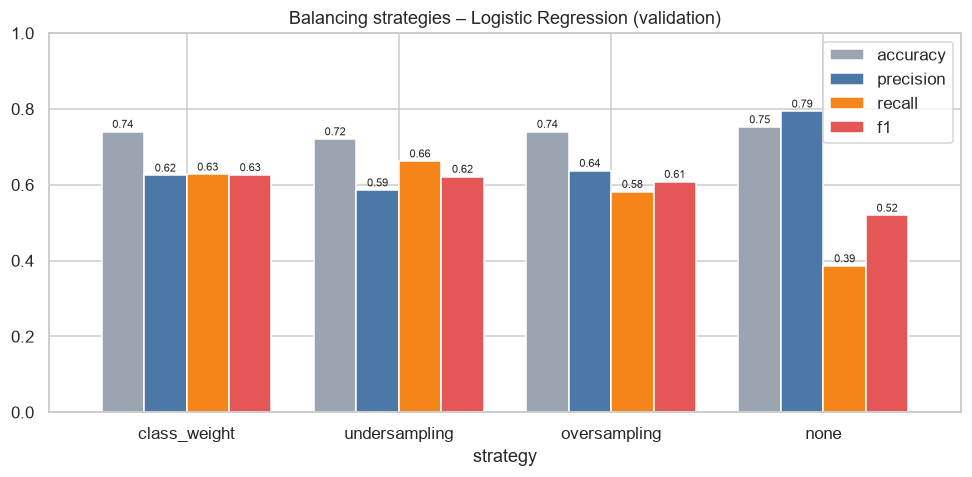

In [4]:
lr_table = lr_table.sort_values("f1", ascending=False)       # best strategy first
display(lr_table.round(4))

# Difference with the reference ("none"): positive = better than doing nothing
ref = lr_table.loc["none", ["accuracy", "precision", "recall", "f1"]]
print("Difference with the reference 'none':")
display((lr_table[["accuracy", "precision", "recall", "f1"]] - ref).round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
lr_table[["accuracy", "precision", "recall", "f1"]].plot(kind="bar", ax=ax, width=0.8, rot=0,
                                                       color=["#9AA5B1", "#4C78A8", "#F58518", "#E45756"])
ax.set_ylim(0, 1); ax.set_title("Balancing strategies – Logistic Regression (validation)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=7, padding=1)       # value above each bar
savefig(fig, P.figures / "f1_by_strategy.png")

**Reading.** Look at where the gain comes from: the delta table shows precision going down and recall going up. A strategy is useful if the **F1 rises**, i.e. if the recall gain
is larger than the precision loss. Accuracy may drop: it is dominated by the majority class and is not our criterion. **Warning:** the validation set has only
1,324 tweets (459 offensive), so differences of one or two F1 points between strategies can be noise; large gaps are meaningful.

<a id="5"></a>
## 5. Precision / recall trade-off
Each point is one strategy. Moving right means finding more offensive tweets; moving up means fewer false alarms.

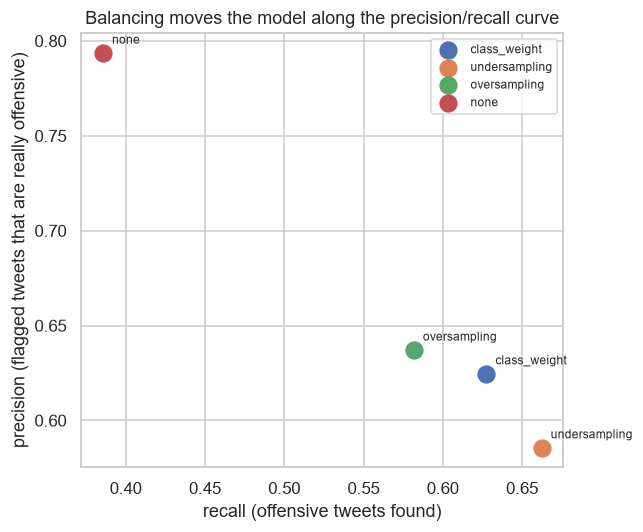

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
for s, r in lr_table.iterrows():
    ax.scatter(r["recall"], r["precision"], s=120, label=s)                      # one point per strategy
    ax.annotate(s, (r["recall"], r["precision"]), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set_xlabel("recall (offensive tweets found)"); ax.set_ylabel("precision (flagged tweets that are really offensive)")
ax.set_title("Balancing moves the model along the precision/recall curve"); ax.legend(fontsize=8)
savefig(fig, P.figures / "precision_recall_tradeoff.png")

**Reading.** Balancing usually **raises recall** (more offensive tweets are found) and **lowers precision** (more normal tweets are wrongly flagged):
the unbalanced model sits at the top-left (precise but misses many), the balanced ones move towards the right. Accuracy can go down while the F1 of the offensive class goes up.
Which side to favour depends on the application: an automatic moderation tool that sends tweets to a human tolerates false alarms, whereas a fully automatic ban would not.

<a id="6"></a>
## 6. Confusion matrices (validation)
The confusion matrices show **how** each strategy is wrong:

* **false negatives** (offensive tweets predicted non-offensive) → hurt recall;
* **false positives** (non-offensive tweets predicted offensive) → hurt precision.

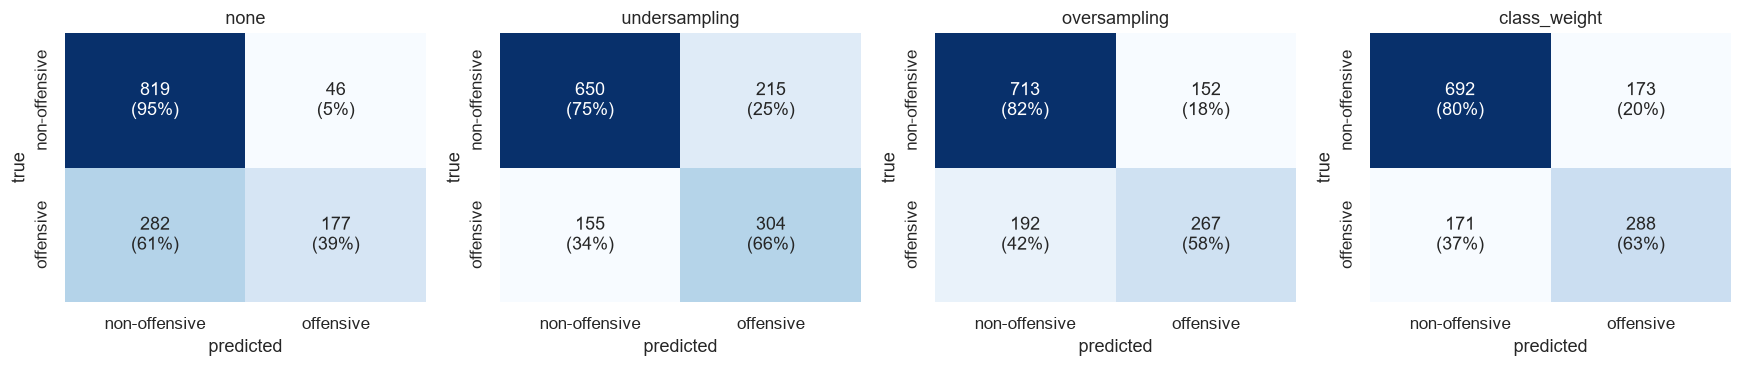

In [6]:
# One heatmap per strategy, in the order of STRATEGIES
fig = plot_confusion_matrices({k: lr_cms[k] for k in STRATEGIES}, ncols=4, figsize_per=(4.0, 3.5))
savefig(fig, P.figures / "confusion_matrices_strategies.png")

**Reading.** Compare the bottom-left cell (missed offensive tweets) with the top-right cell (false alarms): balancing shrinks the first and inflates the second.
The best strategy is the one that reduces the missed tweets the most for the smallest increase in false alarms.

<a id="7"></a>
## 7. Is the conclusion model-specific? Same strategies with a linear SVM
A conclusion drawn with one model may not hold for another. We repeat the experiment with a **linear SVM**, using exactly the same features, strategies and validation set.

In [7]:
svm_table, svm_cms = run_strategies(svm)
svm_table = svm_table.sort_values("f1", ascending=False)
display(svm_table.round(4))
print("(Naive Bayes / KNN have no class_weight option: for them 'class_weight' falls back to oversampling.)")

,train_rows,pct_offensive_in_train,class_weight,accuracy,precision,recall,f1
strategy,,,,,,,
undersampling,7882,50.0,NaN,0.6994,0.5540,0.6819,0.6113
none,11916,33.1,NaN,0.7492,0.6759,0.5316,0.5951
class_weight,11916,33.1,balanced,0.7221,0.6018,0.5861,0.5938
oversampling,15950,50.0,NaN,0.7213,0.6077,0.5534,0.5792


(Naive Bayes / KNN have no class_weight option: for them 'class_weight' falls back to oversampling.)


**Reading.** Compare the two models: (1) which strategy is best for each, (2) how much the F1 gain is, (3) how the models compare **without** balancing.
If the best strategy differs, or the gain is small for one model, the effect of balancing is **model-dependent** and must be re-checked for every model
(notebook 06 trains all five models with the chosen strategy and notebook 07 compares them).

<a id="8"></a>
## 8. Decision
The code reads the tables and prints the setting to copy into `src/config.py`.

In [8]:
best = lr_table["f1"].idxmax()                      # strategy with the highest validation F1 (Logistic Regression)
print(f"Best strategy for Logistic Regression: {best}")
print(f"  F1 original     = {lr_table.loc['none', 'f1']:.4f}  ->  F1 {best} = {lr_table.loc[best, 'f1']:.4f}")
print(f"  recall original = {lr_table.loc['none', 'recall']:.4f}  ->  recall {best} = {lr_table.loc[best, 'recall']:.4f}")
print(f"Best strategy for SVM: {svm_table['f1'].idxmax()}")
print(f"\nSetting to copy into src/config.py:  BALANCING = \"{best}\"")

Best strategy for Logistic Regression: class_weight
  F1 original     = 0.5191  ->  F1 class_weight = 0.6261
  recall original = 0.3856  ->  recall class_weight = 0.6275
Best strategy for SVM: undersampling

Setting to copy into src/config.py:  BALANCING = "class_weight"


### Conclusion (results of the delivered run; re-check the tables above if you re-run)
| Strategy (Logistic Regression) | Precision | Recall | F1 (offensive) | Accuracy |
|---|---|---|---|---|
| none (original) | 0.794 | 0.386 | 0.519 | 0.752 |
| undersampling | 0.586 | 0.662 | 0.622 | 0.721 |
| oversampling | 0.637 | 0.582 | 0.608 | 0.740 |
| **class_weight** | **0.625** | **0.627** | **0.626** | 0.740 |

- Balancing raises the **F1 of the offensive class by about +0.10** (0.519 → 0.626), mainly through recall (0.39 → 0.63), at the price of precision (0.79 → 0.62).
  Accuracy drops slightly, which is expected and acceptable: it was inflated by the majority class.
- `class_weight` gives the best F1, is the simplest (no data duplicated or thrown away, same TF-IDF matrix) and gives a good precision/recall balance.
- With a linear SVM the picture is more nuanced: recall rises with every strategy (0.53 → 0.55–0.68) but the **F1 gain is small**; only undersampling beats the
  original (0.611 vs 0.595), `class_weight` is on par (0.594) and oversampling is lower (0.579). The unbalanced SVM is already much better than the unbalanced
  Logistic Regression (0.595 vs 0.519). Balancing therefore helps most for Logistic Regression, and its effect is model-dependent.
- The test set was **not** used. **Decision:** `BALANCING = "class_weight"` (already set in `src/config.py`); for Naive Bayes and KNN, which have no
  `class_weight` option, the code automatically falls back to oversampling.

<a id="9"></a>
## 9. Creating the balanced training set
Once the best strategy is chosen, we can **materialise** it: build the balanced training set and save it as a **new file**, `train_balanced.csv`.

Rules followed here:

* only the **training rows** are balanced; `val_final.csv` and `test_final.csv` are never touched and keep their original distribution;
* `train_final.csv` is **not overwritten** (a new file is written), so the experiments above can always be reproduced;
* only **resampling** strategies (undersampling / oversampling) change rows. `class_weight` changes the **loss**, not the data, so there is nothing to
  materialise for it. In that case the file is built with **oversampling** (the same fallback the project uses for Naive Bayes and KNN, which have no `class_weight`), and this is printed explicitly.
* Oversampling **duplicates** offensive tweets, so this file must never be split again for cross-validation: copies of the same tweet would land in both
  the training and the validation fold and inflate the scores.

In [9]:
# Strategy used to build the file: the best one if it is a resampling strategy, otherwise oversampling
if best in ("undersampling", "oversampling"):
    file_strategy = best
else:
    file_strategy = "oversampling"
    print(f"Best strategy is '{best}' (a loss weight, not a data change) -> the balanced file is built with oversampling instead.")

# Row indices selected by the strategy (same seed as in the experiments -> same rows)
idx = resample_indices(y_train, file_strategy)
balanced = train.iloc[idx].reset_index(drop=True)          # original rows, selected / duplicated / shuffled

# Checks: the classes must now be equal in size, and the original data must be unchanged
share_before, share_after = 100 * y_train.mean(), 100 * balanced["label"].mean()
print(f"strategy used     : {file_strategy}")
print(f"rows              : {len(train)} -> {len(balanced)}")
print(f"offensive share   : {share_before:.1f} % -> {share_after:.1f} %")
print("class counts      :", balanced["label"].value_counts().to_dict())
assert abs(share_after - 50.0) < 0.5, "the balanced set is not balanced"
assert len(train) == len(pd.read_csv(train_path, keep_default_na=False)), "train_final.csv was modified"

balanced.to_csv(P.processed / "train_balanced.csv", index=False)       # NEW file; train_final.csv stays as it is
print("Saved:", P.processed / "train_balanced.csv")
display(balanced[["text", "text_clean", "label"]].head(5))

Best strategy is 'class_weight' (a loss weight, not a data change) -> the balanced file is built with oversampling instead.
strategy used     : oversampling
rows              : 11916 -> 15950
offensive share   : 33.1 % -> 50.0 %
class counts      : {1: 7975, 0: 7975}
Saved: C:\Users\ASUS\Desktop\TweetEval-offensiveML\data\processed\train_balanced.csv


,text,text_clean,label
0,@user @user Beware of rightist false flags like the narrative of the OK sign being a white nationalist dog whistle. ...,user user beware rightist false flag like narrative ok sign white nationalist dog whistle not theresistance resist b...,1
1,@user @user @user I absolutely agree!! I have tried rallying people on Twitter. Asking them to follow each other. St...,user user user absolutely agree try rally people twitter ask follow strength number vote work poll early election el...,0
2,@user @user If Brookee Baldwin and Erin Burnett start showing cleavage to their Boobies CNN just might.,user user brookee baldwin erin burnett start show cleavage booby cnn might,1
3,@user Thank you for proving my point. You are foulmouthed trash,user thank prove point foulmouthed trash,1
4,@user @user They've been trying. A couple of veterans happened 2 b assaulted by ANTIFA. Wrong!! They were surprised!...,user user try couple veteran happen 2 b assault antifa wrong surprise fight kinda break protest,0


**Reading.**
- The offensive share goes from about 33 % to 50 %. With undersampling the file is **smaller** than `train_final.csv` (non-offensive tweets removed); with oversampling it is **larger**
  (offensive tweets repeated), so some rows appear several times.
- The `assert` lines guarantee that the classes are equal and that `train_final.csv` still has its original size.
- **How to use the file.** Train a model on `train_balanced.csv` and evaluate it on `val_final.csv` / `test_final.csv` (original distribution). Fit TF-IDF on the training rows you actually train on.
  If you keep `class_weight` as the project strategy (the later notebooks apply it at training time), you do **not** need this file: it is provided for models or tools that cannot weight the classes.
- Validation and test files are untouched, so scores remain comparable with all previous notebooks.

<a id="10"></a>
## 10. Saving the results
Both tables (Logistic Regression and SVM) are saved in one CSV, with a `model` column, for the report and the final notebook.

In [10]:
out_lr  = lr_table.copy();  out_lr["model"]  = "logistic_regression"
out_svm = svm_table.copy(); out_svm["model"] = "svm"
pd.concat([out_lr, out_svm]).round(5).to_csv(P.metrics / "balancing_comparison.csv")      # index = strategy name
print("Saved:", P.metrics / "balancing_comparison.csv")
print("Figures:", sorted(p.name for p in Path(P.figures).glob("*.png")))

Saved: C:\Users\ASUS\Desktop\TweetEval-offensiveML\results\metrics\04_class_balance_experiments\balancing_comparison.csv
Figures: ['confusion_matrices_strategies.png', 'f1_by_strategy.png', 'precision_recall_tradeoff.png']


**Reading.** The CSV contains one row per (model, strategy) with precision, recall, F1 and accuracy, and can be pasted directly into the report.